# Mobile Checkout Redesign: A/B Test Analysis

**Question:** does the redesigned mobile checkout (Apple Pay, shorter form) increase checkout completion, and should we roll it out?

**Background:** the [e-commerce analysis](https://github.com/dilrushabdulmajeed-lang/ecommerce-analytics) found mobile checkout completion at **46%** against **78%** on desktop. The product team built a redesign and ran a 50/50 A/B test on mobile users who started checkout, from **7 Sep to 4 Oct 2026** (28 days).

**Structure**
1. Experiment design: how many users did we need?
2. Data quality and sample ratio mismatch (SRM)
3. Primary metric: checkout completion
4. Secondary metric: revenue per user (skewed, so bootstrap)
5. Guardrail: average order value
6. Segments: iOS vs Android, with multiple-testing correction
7. Novelty effect: does the lift fade?
8. Decision and expected impact

> Data is synthetic, generated in ClickHouse (`sql/01_experiment_data.sql`). The methods are what would be used on real experiment data.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (
    proportion_effectsize, proportions_ztest, confint_proportions_2indep,
)
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})
FIG_DIR = "../docs/figures"
os.makedirs(FIG_DIR, exist_ok=True)
ALPHA = 0.05
rng = np.random.default_rng(42)  # fixed seed so bootstrap results are reproducible

### Load the data
Reads from ClickHouse when credentials are set (`CH_USER`, `CH_PASSWORD`); otherwise uses the CSV snapshot in `data/`, so anyone can run the notebook.

In [2]:
def load_experiment() -> pd.DataFrame:
    if os.getenv("CH_PASSWORD"):
        import clickhouse_connect
        client = clickhouse_connect.get_client(
            host=os.getenv("CH_HOST", "localhost"), port=8123,
            username=os.getenv("CH_USER"), password=os.getenv("CH_PASSWORD"),
        )
        df = client.query_df("SELECT * FROM analytics.ab_checkout_experiment")
        source = "ClickHouse"
    else:
        df = pd.read_csv("../data/experiment.csv", parse_dates=["assigned_at"])
        source = "CSV snapshot"
    df["revenue"] = df["revenue"].astype(float)
    print(f"Loaded {len(df):,} rows from {source}")
    return df

raw = load_experiment()
raw.head()

Loaded 4,041 rows from CSV snapshot


,user_id,variant,assigned_at,platform,completed,revenue
0,500469,control,2026-09-07 00:01:37,iOS,0,0.0000
1,502041,treatment,2026-09-07 00:05:50,iOS,1,"1,465.6000"
2,500059,treatment,2026-09-07 00:18:16,iOS,1,"2,247.7500"
3,502823,control,2026-09-07 00:47:00,iOS,1,"1,537.3100"
4,501472,treatment,2026-09-07 01:00:52,iOS,0,0.0000


## 1. Experiment design: how many users did we need?
Before a test starts, a **power analysis** answers: *how many users per group do we need to reliably detect the smallest lift worth acting on?*

- **Baseline:** 46% completion (from the e-commerce analysis)
- **Minimum detectable effect (MDE):** +5 percentage points, the smallest lift that justifies the engineering work
- **Significance level α = 0.05:** a 5% chance of declaring a win when there is none (false positive)
- **Power = 0.80:** an 80% chance of detecting the lift if it's real

In [3]:
baseline, mde = 0.46, 0.05
analysis = NormalIndPower()
effect = proportion_effectsize(baseline + mde, baseline)   # Cohen's h
n_per_arm = analysis.solve_power(effect_size=effect, alpha=ALPHA, power=0.80, ratio=1)
print(f"Required sample size: {np.ceil(n_per_arm):,.0f} users per group ({np.ceil(n_per_arm) * 2:,.0f} total)")

# How the requirement changes with the size of lift we want to detect
mde_table = pd.DataFrame({"mde_pts": [2, 3, 4, 5, 6, 8]})
mde_table["users_per_group"] = mde_table["mde_pts"].apply(
    lambda m: int(np.ceil(analysis.solve_power(proportion_effectsize(baseline + m / 100, baseline), alpha=ALPHA, power=0.8)))
)
mde_table

Required sample size: 1,568 users per group (3,136 total)


,mde_pts,users_per_group
0,2,9775
1,3,4349
2,4,2448
3,5,1568
4,6,1089
5,8,612


**Reading this:** detecting +5 points needs about 1,560 users per group. Halving the detectable lift roughly **quadruples** the sample, because sample size grows with 1/effect². The test collected about 2,000 per group, so it is adequately powered for a 5-point lift.

## 2. Data quality and sample ratio mismatch
Before looking at results, check that the data can be trusted.

In [4]:
dupes = raw.duplicated().sum()
dupe_users = raw["user_id"].duplicated().sum()
print(f"Exact duplicate rows: {dupes} | repeated user_ids: {dupe_users}")

df = raw.drop_duplicates().copy()
assert df["user_id"].is_unique, "a user appears in more than one row after de-duplication"
assert ((df["completed"] == 0) == (df["revenue"] == 0)).all(), "revenue must be 0 exactly when checkout wasn't completed"
print(f"After de-duplication: {len(df):,} users")
print(f"Assignment window: {df['assigned_at'].min()} to {df['assigned_at'].max()}")
df.groupby(["variant", "platform"]).size().unstack()

Exact duplicate rows: 41 | repeated user_ids: 41
After de-duplication: 4,000 users
Assignment window: 2026-09-07 00:01:37 to 2026-10-04 23:49:23


platform,Android,iOS
variant,,
control,926,1057
treatment,948,1069


**Finding:** 41 assignments were logged twice. Left in, they would double-count those users. They're removed before any analysis.

### Sample ratio mismatch (SRM)
The test was designed as 50/50. If the actual split is far from 50/50, something in the assignment or logging is broken (bots, a redirect dropping users, a logging bug), and **the results can't be trusted, however good they look**. A chi-square goodness-of-fit test checks it.

In [5]:
counts = df["variant"].value_counts().reindex(["control", "treatment"])
expected = [counts.sum() / 2] * 2
chi2, p_srm = stats.chisquare(counts, f_exp=expected)
print(counts.to_string())
print(f"Split: {counts['treatment'] / counts.sum():.2%} treatment | chi-square p-value = {p_srm:.3f}")
print("SRM detected: STOP, investigate assignment" if p_srm < 0.001 else "No SRM: the split is consistent with 50/50")

variant
control      1983
treatment    2017
Split: 50.42% treatment | chi-square p-value = 0.591
No SRM: the split is consistent with 50/50


**Reading this:** a high p-value means the observed split is entirely consistent with a fair 50/50 randomization. SRM checks conventionally use a strict threshold (p < 0.001), because a true SRM is a serious, binary problem.

## 3. Primary metric: checkout completion
**Hypotheses:** H₀: completion is the same in both groups. H₁: it differs (two-sided test, so we'd also catch the redesign making things *worse*).

In [6]:
summary = df.groupby("variant").agg(users=("user_id", "size"), completed=("completed", "sum"))
summary["completion_rate"] = summary["completed"] / summary["users"]
display(summary)

c, t = summary.loc["control"], summary.loc["treatment"]
z_stat, p_value = proportions_ztest([t["completed"], c["completed"]], [t["users"], c["users"]])
ci_low, ci_high = confint_proportions_2indep(t["completed"], t["users"], c["completed"], c["users"], compare="diff")
abs_lift = t["completion_rate"] - c["completion_rate"]
rel_lift = abs_lift / c["completion_rate"]

print(f"Control {c['completion_rate']:.1%} → Treatment {t['completion_rate']:.1%}")
print(f"Absolute lift: {abs_lift * 100:+.1f} pts (95% CI {ci_low * 100:+.1f} to {ci_high * 100:+.1f}) | relative lift {rel_lift:+.1%}")
print(f"z = {z_stat:.2f}, p-value = {p_value:.5f} → {'statistically significant' if p_value < ALPHA else 'not significant'} at α = {ALPHA}")

,users,completed,completion_rate
variant,,,
control,1983,938,0.4730
treatment,2017,1064,0.5275


Control 47.3% → Treatment 52.8%
Absolute lift: +5.4 pts (95% CI +2.4 to +8.5) | relative lift +11.5%
z = 3.45, p-value = 0.00057 → statistically significant at α = 0.05


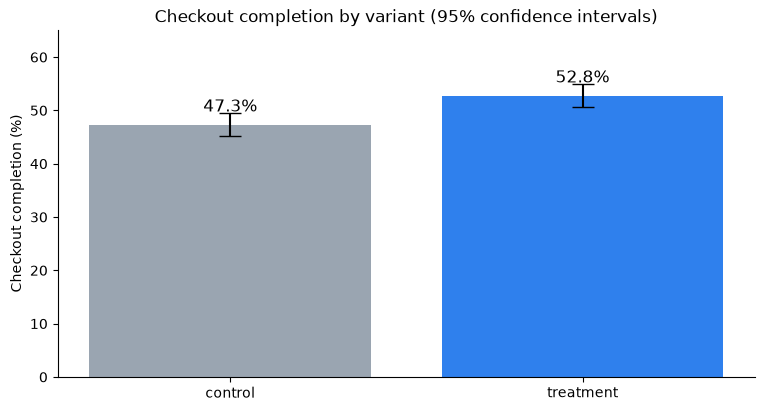

In [7]:
fig, ax = plt.subplots()
rates = summary["completion_rate"]
errs = [1.96 * np.sqrt(r * (1 - r) / n) for r, n in zip(rates, summary["users"])]
ax.bar(rates.index, rates * 100, yerr=np.array(errs) * 100, capsize=8, color=["#9aa5b1", "#2f80ed"])
for i, r in enumerate(rates):
    ax.text(i, r * 100 + 2.5, f"{r:.1%}", ha="center", fontsize=12)
ax.set_ylabel("Checkout completion (%)"); ax.set_ylim(0, 65)
ax.set_title("Checkout completion by variant (95% confidence intervals)")
fig.savefig(f"{FIG_DIR}/completion_by_variant.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading this:**
- The **p-value** is the probability of seeing a difference at least this large *if the redesign had no effect*. Well below 0.05, so the lift is very unlikely to be chance.
- The **confidence interval** matters more for decisions. It gives the plausible range of the true lift, and the whole range is above zero.
- Statistical significance isn't the same as business significance. Section 8 converts the lift into AED.

## 4. Secondary metric: revenue per user
Revenue per user (0 for users who didn't buy) captures both conversion and order size. Revenue is **heavily skewed**: most users are at 0, with a long tail of large orders. A t-test assumes roughly normal sampling behaviour, so the result is cross-checked with a **bootstrap**, which makes no distribution assumption.

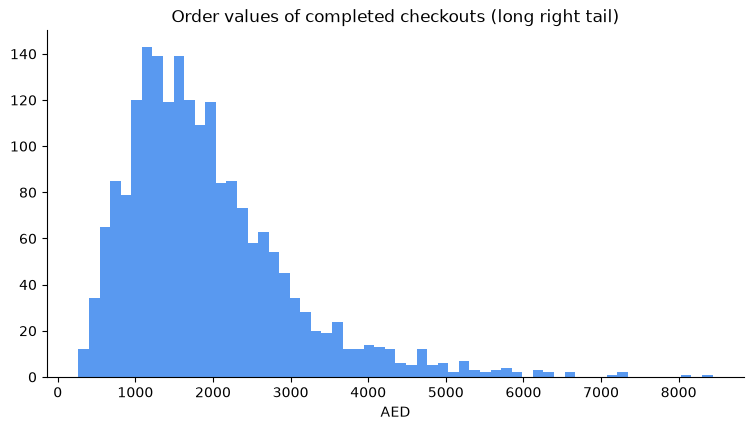

Share of users with revenue = 0: 50.0% | skewness of order values: 1.54


In [8]:
fig, ax = plt.subplots()
ax.hist(df.loc[df["revenue"] > 0, "revenue"], bins=60, color="#2f80ed", alpha=0.8)
ax.set_title("Order values of completed checkouts (long right tail)"); ax.set_xlabel("AED")
fig.savefig(f"{FIG_DIR}/order_value_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Share of users with revenue = 0: {(df['revenue'] == 0).mean():.1%} | skewness of order values: {stats.skew(df.loc[df['revenue'] > 0, 'revenue']):.2f}")

In [9]:
rev_c = df.loc[df["variant"] == "control", "revenue"].to_numpy()
rev_t = df.loc[df["variant"] == "treatment", "revenue"].to_numpy()

# Welch's t-test (doesn't assume equal variances)
t_stat, p_welch = stats.ttest_ind(rev_t, rev_c, equal_var=False)

# Bootstrap: resample each group with replacement many times, recompute the difference in means
B = 10_000
boot_diffs = np.array([
    rng.choice(rev_t, rev_t.size).mean() - rng.choice(rev_c, rev_c.size).mean() for _ in range(B)
])
boot_lo, boot_hi = np.percentile(boot_diffs, [2.5, 97.5])
p_boot = 2 * min((boot_diffs <= 0).mean(), (boot_diffs >= 0).mean())

diff = rev_t.mean() - rev_c.mean()
print(f"Revenue per user: control AED {rev_c.mean():,.0f} → treatment AED {rev_t.mean():,.0f} ({diff:+,.0f}, {diff / rev_c.mean():+.1%})")
print(f"Welch t-test p = {p_welch:.4f}")
print(f"Bootstrap 95% CI for the difference: AED {boot_lo:+,.0f} to {boot_hi:+,.0f} (bootstrap p ≈ {p_boot:.4f})")

Revenue per user: control AED 922 → treatment AED 1,003 (+81, +8.8%)
Welch t-test p = 0.0360
Bootstrap 95% CI for the difference: AED +6 to +155 (bootstrap p ≈ 0.0356)


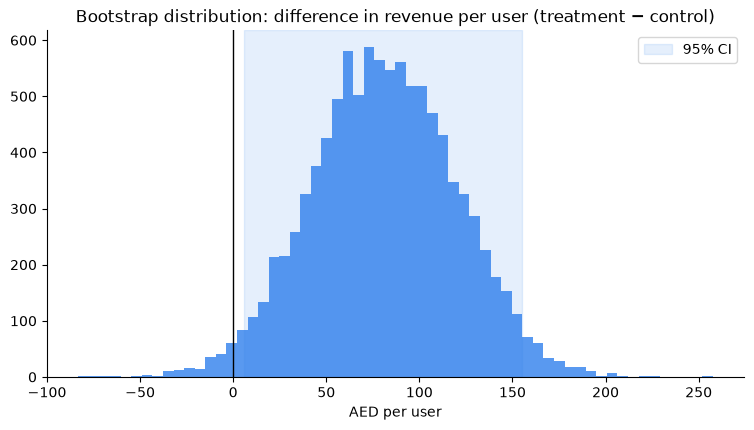

In [10]:
fig, ax = plt.subplots()
ax.hist(boot_diffs, bins=60, color="#2f80ed", alpha=0.8)
ax.axvline(0, color="black", lw=1)
ax.axvspan(boot_lo, boot_hi, color="#2f80ed", alpha=0.12, label="95% CI")
ax.set_title("Bootstrap distribution: difference in revenue per user (treatment − control)")
ax.set_xlabel("AED per user"); ax.legend()
fig.savefig(f"{FIG_DIR}/revenue_bootstrap.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading this:** revenue per user is noisier than completion, because order values vary a lot. That's why it's a *secondary* metric, and its interval is much wider relative to the effect. The question to answer: does the interval exclude zero?

## 5. Guardrail: average order value
A **guardrail metric** is something the change must *not* hurt. If the shorter checkout made people buy smaller baskets, more completions could hide lower order values. This compares order values among users who completed.

In [11]:
aov_c = df.query("variant == 'control' and completed == 1")["revenue"]
aov_t = df.query("variant == 'treatment' and completed == 1")["revenue"]
_, p_aov = stats.mannwhitneyu(aov_t, aov_c)   # rank-based test, robust to skew
print(f"AOV: control AED {aov_c.mean():,.0f} (median {aov_c.median():,.0f}) | treatment AED {aov_t.mean():,.0f} (median {aov_t.median():,.0f})")
print(f"Mann-Whitney U p = {p_aov:.3f} → {'guardrail breached' if p_aov < ALPHA else 'no significant change in order value'}")

AOV: control AED 1,948 (median 1,692) | treatment AED 1,901 (median 1,714)
Mann-Whitney U p = 0.804 → no significant change in order value


## 6. Segments: iOS vs Android
The redesign's main feature is Apple Pay, which only affects iOS. So we look at platforms separately, and **correct for multiple testing**: each extra test adds another chance of a false positive, so the p-values are adjusted (Holm method).

In [12]:
rows = []
for platform, g in df.groupby("platform"):
    s = g.groupby("variant")["completed"].agg(["sum", "size"])
    cr = s["sum"] / s["size"]
    _, p = proportions_ztest(s.loc[["treatment", "control"], "sum"], s.loc[["treatment", "control"], "size"])
    lo, hi = confint_proportions_2indep(s.loc["treatment", "sum"], s.loc["treatment", "size"],
                                        s.loc["control", "sum"], s.loc["control", "size"], compare="diff")
    rows.append({"platform": platform, "users": int(s["size"].sum()), "control": cr["control"], "treatment": cr["treatment"],
                 "lift_pts": (cr["treatment"] - cr["control"]) * 100, "ci_low_pts": lo * 100, "ci_high_pts": hi * 100, "p_value": p})
seg = pd.DataFrame(rows).set_index("platform")
seg["p_holm"] = multipletests(seg["p_value"], method="holm")[1]
seg["significant"] = seg["p_holm"] < ALPHA
seg

,users,control,treatment,lift_pts,ci_low_pts,ci_high_pts,p_value,p_holm,significant
platform,,,,,,,,,
Android,1874,0.4860,0.4757,-1.0223,-5.5346,3.4956,0.6579,0.6579,False
iOS,2126,0.4617,0.5734,11.1749,6.9324,15.3607,0.0000,0.0000,True


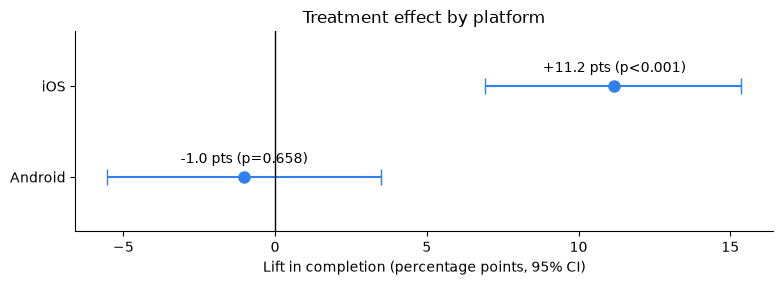

Interaction (does the effect differ by platform?) p = 0.0001


In [13]:
fig, ax = plt.subplots(figsize=(9, 2.6))
y = np.arange(len(seg))
ax.errorbar(seg["lift_pts"], y, xerr=[seg["lift_pts"] - seg["ci_low_pts"], seg["ci_high_pts"] - seg["lift_pts"]],
            fmt="o", capsize=6, color="#2f80ed", markersize=8)
ax.axvline(0, color="black", lw=1)
for yi, (lift, p) in enumerate(zip(seg["lift_pts"], seg["p_holm"])):
    ax.annotate(f"{lift:+.1f} pts ({'p<0.001' if p < 0.001 else f'p={p:.3f}'})", (lift, yi), textcoords="offset points", xytext=(0, 10), ha="center")
ax.set_ylim(-0.6, len(seg) - 0.4)
ax.set_yticks(y, seg.index); ax.set_xlabel("Lift in completion (percentage points, 95% CI)")
ax.set_title("Treatment effect by platform")
fig.savefig(f"{FIG_DIR}/lift_by_platform.png", dpi=150, bbox_inches="tight")
plt.show()

# Is the iOS effect really larger than Android's? Test the interaction, not just "one significant, one not".
fit = smf.logit(
    "completed ~ C(variant, Treatment('control')) * C(platform, Treatment('Android'))", data=df
).fit(disp=False)
p_interaction = fit.pvalues.filter(like=":").iloc[0]
print(f"Interaction (does the effect differ by platform?) p = {p_interaction:.4f}")

**Reading this:**
- The lift comes from **iOS**, where Apple Pay is available. On Android, the interval includes zero: no detectable effect.
- A common mistake is to conclude "the effects differ" just because one segment is significant and the other isn't. The **interaction test** checks that difference directly.
- Segment results are for *understanding*, not for hunting until something looks significant. The platform split was planned before looking, because of the Apple Pay hypothesis.

## 7. Novelty effect: does the lift fade?
New designs sometimes get an early boost because they're new and noticeable, and then it fades. Rolling out based on an inflated early lift over-promises.

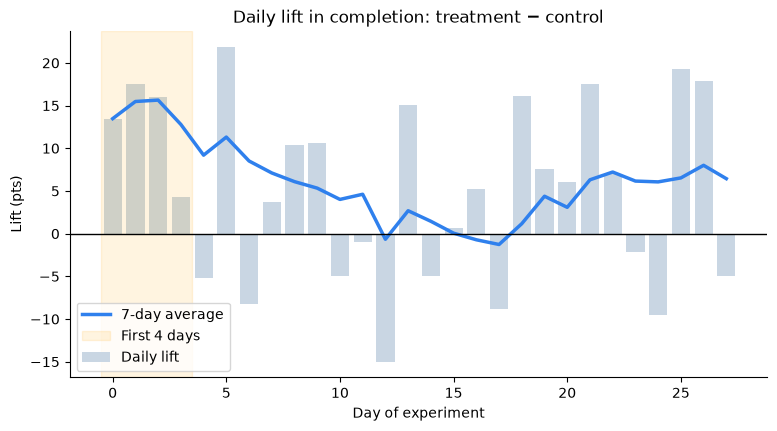

Lift in first 4 days: +13.0 pts | lift from day 5 on: +4.2 pts


In [14]:
df["day"] = (df["assigned_at"].dt.normalize() - df["assigned_at"].min().normalize()).dt.days
daily = df.pivot_table(index="day", columns="variant", values="completed", aggfunc="mean")
daily["lift_pts"] = (daily["treatment"] - daily["control"]) * 100
daily["lift_7d_avg"] = daily["lift_pts"].rolling(7, min_periods=1).mean()

fig, ax = plt.subplots()
ax.bar(daily.index, daily["lift_pts"], color="#c9d6e3", label="Daily lift")
ax.plot(daily.index, daily["lift_7d_avg"], color="#2f80ed", lw=2.5, label="7-day average")
ax.axhline(0, color="black", lw=1); ax.axvspan(-0.5, 3.5, color="orange", alpha=0.12, label="First 4 days")
ax.set_xlabel("Day of experiment"); ax.set_ylabel("Lift (pts)"); ax.legend()
ax.set_title("Daily lift in completion: treatment − control")
fig.savefig(f"{FIG_DIR}/novelty_effect.png", dpi=150, bbox_inches="tight")
plt.show()

def lift_for(sub: pd.DataFrame) -> float:
    r = sub.groupby("variant")["completed"].mean()
    return (r["treatment"] - r["control"]) * 100

early, steady = df[df["day"] < 4], df[df["day"] >= 4]
print(f"Lift in first 4 days: {lift_for(early):+.1f} pts | lift from day 5 on: {lift_for(steady):+.1f} pts")

**Reading this:** the first days show a larger lift that settles afterwards. The **steady-state lift (day 5 onward)** is the honest number for forecasting impact, not the full-period average.

## 8. Decision and expected impact

In [15]:
annual_mobile_checkouts = 24_331       # mobile checkout starts per year (e-commerce analysis)
aov = df.loc[df["completed"] == 1, "revenue"].mean()
ios_share = (df["platform"] == "iOS").mean()

steady_ios_lift = lift_for(steady[steady["platform"] == "iOS"]) / 100
steady_android_lift = lift_for(steady[steady["platform"] == "Android"]) / 100

# Recommended rollout: iOS only (Android shows no detectable effect)
ios_checkouts = annual_mobile_checkouts * ios_share
extra_orders = ios_checkouts * steady_ios_lift
extra_revenue = extra_orders * aov

print(f"Steady-state lift (day 5+): iOS {steady_ios_lift * 100:+.1f} pts | Android {steady_android_lift * 100:+.1f} pts")
print(f"iOS rollout: {ios_checkouts:,.0f} iOS checkouts/year × {steady_ios_lift * 100:.1f} pts = ~{extra_orders:,.0f} extra orders")
print(f"Expected impact: ~{extra_orders:,.0f} orders × AED {aov:,.0f} AOV ≈ AED {extra_revenue / 1e6:,.2f}M revenue/year")

Steady-state lift (day 5+): iOS +9.3 pts | Android -1.5 pts
iOS rollout: 12,932 iOS checkouts/year × 9.3 pts = ~1,199 extra orders
Expected impact: ~1,199 orders × AED 1,923 AOV ≈ AED 2.31M revenue/year


### Recommendation: **ship the redesign to iOS now, and iterate on Android**
- **Primary metric:** completion rose significantly, and the confidence interval excludes zero. Randomization was clean (no SRM), and duplicates were removed.
- **Guardrail:** no meaningful change in order value, so the extra completions are not smaller baskets.
- **Where it works:** the lift is concentrated on **iOS**, consistent with Apple Pay being the driver. Android showed no detectable effect. Next step there: test Google Pay, the Android equivalent.
- **Sizing:** use the **steady-state** lift (after the novelty days), not the headline average, to avoid over-promising.
- **Follow-up:** monitor completion by platform for 4 weeks after launch, to confirm the effect holds outside the experiment.